In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
warnings.filterwarnings('ignore')

In [2]:
datafolder = "../data"
spadl_h5   = os.path.join(datafolder, "women-statsbomb3.h5")

## Load factor scores

In [3]:
efa_df = pd.read_hdf(spadl_h5, "efa_tempo_index")
print(f"Rows: {len(efa_df):,}")
print(efa_df.columns.tolist())
efa_df.head(3)

Rows: 39,995
['game_id', 'possession', 'possession_team_id', 'tournament', 'gender', 'TI_efa', 'TI_horst', 'F1', 'F2', 'F3']


,game_id,possession,possession_team_id,tournament,gender,TI_efa,TI_horst,F1,F2,F3
0,4020846,2,865,WEURO2025,Women,0.122384,1.143743,0.122384,0.414033,0.007227
1,4020846,4,865,WEURO2025,Women,0.375292,0.737501,0.375292,0.134878,-0.014533
2,4020846,5,865,WEURO2025,Women,0.009955,1.003642,0.009955,1.426399,1.172717


## Fit final GMM for TI_horst

  K=2  BIC=   111,807   Silhouette= 0.5542
  K=3  BIC=   111,969   Silhouette= 0.5140
  K=4  BIC=   111,956   Silhouette= 0.5153
  K=5  BIC=   111,953   Silhouette= 0.5200
  K=6  BIC=   112,009   Silhouette= 0.5112
  K=7  BIC=   111,991   Silhouette= 0.5221
  K=8  BIC=   111,989   Silhouette= 0.5223


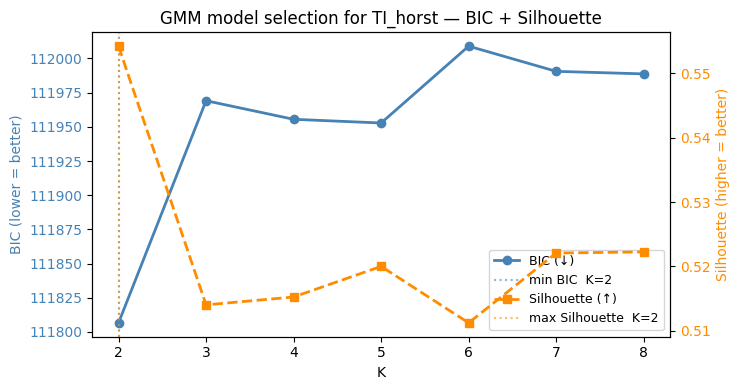


BIC-optimal        : K = 2  (BIC = 111,807)
Silhouette-optimal : K = 2  (s = 0.5542)
→ Both criteria agree.  Selected K = 2


In [4]:
# Prepare features for TI_horst
X_horst = efa_df[['TI_horst']].dropna()
meta_horst = efa_df.loc[X_horst.index, ["game_id","possession","possession_team_id", "tournament","gender"]]

# Option: 'gmm' or 'kmeans'
CLUSTERING_METHOD = 'gmm'

K_RANGE = range(2, 9)
np.random.seed(42)

bic_scores_horst = []
sil_scores_horst = []

if CLUSTERING_METHOD == 'kmeans':
    from sklearn.cluster import KMeans
    for k in K_RANGE:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)
        labels = kmeans.fit_predict(X_horst)
        if len(np.unique(labels)) > 1:
            sil_scores_horst.append(
                silhouette_score(X_horst, labels, sample_size=10_000, random_state=42)
            )
        else:
            sil_scores_horst.append(np.nan)
        print(f"  K={k}  Silhouette={sil_scores_horst[-1]: .4f}")
    
    ks = list(K_RANGE)
    k_sil = ks[int(np.nanargmax(sil_scores_horst))]
    K_OPT_HORST = k_sil

    # ── Single-axis diagnostic plot for KMeans ────────────────────────────────────
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot(ks, sil_scores_horst, 's--', color='darkorange', lw=2, label='Silhouette (↑)')
    ax.axvline(k_sil, color='darkorange', ls=':', alpha=0.6,
                label=f'max Silhouette  K={k_sil}')
    ax.set_xlabel('K')
    ax.set_ylabel('Silhouette (higher = better)', color='darkorange')
    ax.tick_params(axis='y', labelcolor='darkorange')
    ax.set_title('KMeans model selection for TI_horst — Silhouette Only')
    ax.legend(loc='best', fontsize=9)
    plt.tight_layout(); plt.show()

    # ── Decision rule ────────────────────────────────────────────────────────────
    print(f"\nSilhouette-optimal : K = {k_sil}  (s = {np.nanmax(sil_scores_horst):.4f})")
    print(f"→ Selected K = {K_OPT_HORST}")

else:
    for k in K_RANGE:
        gmm = GaussianMixture(n_components=k, covariance_type='full',
                              random_state=42, n_init=5)
        gmm.fit(X_horst)
        labels = gmm.predict(X_horst)
        bic_scores_horst.append(gmm.bic(X_horst))
        if len(np.unique(labels)) > 1:
            sil_scores_horst.append(
                silhouette_score(X_horst, labels, sample_size=10_000, random_state=42)
            )
        else:
            sil_scores_horst.append(np.nan)
        print(f"  K={k}  BIC={bic_scores_horst[-1]:>10,.0f}   "
              f"Silhouette={sil_scores_horst[-1]: .4f}")

    ks = list(K_RANGE)
    k_bic = ks[int(np.argmin(bic_scores_horst))]
    k_sil = ks[int(np.nanargmax(sil_scores_horst))]

    # ── Dual-axis diagnostic plot for GMM ────────────────────────────────────────
    fig, ax1 = plt.subplots(figsize=(7.5, 4))
    ax2 = ax1.twinx()

    l1, = ax1.plot(ks, bic_scores_horst, 'o-', color='steelblue', lw=2, label='BIC (↓)')
    l2, = ax2.plot(ks, sil_scores_horst, 's--', color='darkorange', lw=2, label='Silhouette (↑)')

    ax1.axvline(k_bic, color='steelblue', ls=':', alpha=0.6,
                label=f'min BIC  K={k_bic}')
    ax2.axvline(k_sil, color='darkorange', ls=':', alpha=0.6,
                label=f'max Silhouette  K={k_sil}')

    ax1.set_xlabel('K')
    ax1.set_ylabel('BIC (lower = better)', color='steelblue')
    ax2.set_ylabel('Silhouette (higher = better)', color='darkorange')
    ax1.tick_params(axis='y', labelcolor='steelblue')
    ax2.tick_params(axis='y', labelcolor='darkorange')
    ax1.set_title('GMM model selection for TI_horst — BIC + Silhouette')

    # Combined legend
    lines, labels_ = ax1.get_legend_handles_labels()
    lines2, labels2_ = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels_ + labels2_, loc='best', fontsize=9)
    plt.tight_layout(); plt.show()

    # ── Decision rule ────────────────────────────────────────────────────────────
    print(f"\nBIC-optimal        : K = {k_bic}  (BIC = {min(bic_scores_horst):,.0f})")
    print(f"Silhouette-optimal : K = {k_sil}  (s = {np.nanmax(sil_scores_horst):.4f})")
    if k_bic == k_sil:
        K_OPT_HORST = k_bic
        print(f"→ Both criteria agree.  Selected K = {K_OPT_HORST}")
    else:
        # Disagreement: default to the more parsimonious K (BIC) and flag the conflict
        K_OPT_HORST = k_bic
        print(f"→ Criteria disagree; defaulting to BIC (parsimony).  "
              f"Selected K = {K_OPT_HORST}")


In [5]:
K_OPT_HORST = 2

if 'CLUSTERING_METHOD' not in globals():
    CLUSTERING_METHOD = 'gmm'

if CLUSTERING_METHOD == 'kmeans':
    from sklearn.cluster import KMeans
    kmeans_final_horst = KMeans(
        n_clusters=K_OPT_HORST, random_state=42, n_init=20,
    ).fit(X_horst)
    
    # Re-order cluster IDs so 0 = slowest (lowest center), K-1 = fastest
    _order = np.argsort(kmeans_final_horst.cluster_centers_.ravel())
    _remap = {old: new for new, old in enumerate(_order)}
    labels_horst = np.vectorize(_remap.get)(kmeans_final_horst.labels_)
    
    cluster_mu = kmeans_final_horst.cluster_centers_.ravel()[_order]
    cluster_sd = np.array([X_horst.values[labels_horst == k].std() for k in range(K_OPT_HORST)])
    cluster_pi = np.array([np.mean(labels_horst == k) for k in range(K_OPT_HORST)])
    
    # pseudo-probabilities using KMeans clusters as normal components
    probs_list = []
    for k in range(K_OPT_HORST):
        mu = cluster_mu[k]
        sd = max(cluster_sd[k], 1e-6)
        pi = cluster_pi[k]
        pdf = (1.0 / (np.sqrt(2 * np.pi) * sd)) * np.exp(-0.5 * ((X_horst.values - mu) / sd) ** 2)
        probs_list.append(pdf * pi)
    
    probs_horst = np.column_stack(probs_list)
    row_sums = probs_horst.sum(axis=1, keepdims=True)
    row_sums = np.where(row_sums == 0, 1.0, row_sums)
    probs_horst = probs_horst / row_sums

else:
    gmm_final_horst = GaussianMixture(
        n_components=K_OPT_HORST, covariance_type='full',
        random_state=42, n_init=20,
    ).fit(X_horst)

    # Re-order cluster IDs so 0 = slowest (lowest μ), K-1 = fastest
    _order  = np.argsort(gmm_final_horst.means_.ravel())
    _remap  = {old: new for new, old in enumerate(_order)}
    labels_horst = np.vectorize(_remap.get)(gmm_final_horst.predict(X_horst))
    probs_horst  = gmm_final_horst.predict_proba(X_horst)[:, _order]

    # Component parameters, sorted low → high
    cluster_mu   = gmm_final_horst.means_.ravel()[_order]
    cluster_sd   = np.sqrt(gmm_final_horst.covariances_.ravel())[_order]
    cluster_pi   = gmm_final_horst.weights_[_order]

result_horst = meta_horst.copy()
result_horst['TI_horst'] = X_horst.values
result_horst['cluster']  = labels_horst
result_horst['max_prob'] = probs_horst.max(axis=1)
for k in range(K_OPT_HORST):
    result_horst[f'p_C{k}'] = probs_horst[:, k]

print(f"Selected K = {K_OPT_HORST}")
print("Component parameters (sorted slow → fast):")
for k in range(K_OPT_HORST):
    print(f"  C{k}: μ={cluster_mu[k]:+.3f}  σ={cluster_sd[k]:.3f}  π={cluster_pi[k]:.3f}")
print(f"\nHard-assignment sizes:")
print(result_horst['cluster'].value_counts().sort_index().to_string())
print(f"\nMean posterior confidence (max_prob): {result_horst['max_prob'].mean():.3f}")


Selected K = 2
Component parameters (sorted slow → fast):
  C0: μ=-0.634  σ=1.128  π=0.342
  C1: μ=+0.329  σ=0.736  π=0.658

Hard-assignment sizes:
cluster
0     7942
1    32053

Mean posterior confidence (max_prob): 0.766


In [6]:
# ── Cluster profiling for TI_horst
profile_horst = result_horst.groupby('cluster')[['TI_horst']].mean().round(3)
profile_horst['n'] = result_horst['cluster'].value_counts().sort_index()
profile_horst['pct'] = (profile_horst['n'] / len(result_horst) * 100).round(1)
print("=== Cluster TI_horst profiles ===")
print(profile_horst.to_string())

# ── Gender composition per cluster 
gender_comp_horst = (
    result_horst.groupby(['cluster','gender']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Gender composition (%) ===")
print(gender_comp_horst.to_string())

# ── Tournament composition per cluster
tourn_comp_horst = (
    result_horst.groupby(['cluster','tournament']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Tournament composition (%) ===")
print(tourn_comp_horst.to_string())

=== Cluster TI_horst profiles ===
         TI_horst      n   pct
cluster                       
0          -1.452   7942  19.9
1           0.360  32053  80.1

=== Gender composition (%) ===
gender    Men  Women
cluster             
0        36.3   63.7
1        59.0   41.0

=== Tournament composition (%) ===
tournament  EURO2020  EURO2024  WC2022  WEURO2022  WEURO2025  WWC2023
cluster                                                              
0               10.8      10.5    14.9       14.2       14.3     35.3
1               18.3      17.5    23.1       10.2       10.2     20.6


## Cluster diagnostics, density decomposition & cross-group composition

Six diagnostic panels:

1. **GMM density decomposition** — empirical KDE + fitted mixture density + per-component Gaussian + decision boundary.
2. **Posterior confidence (max p)** — by cluster; quantifies how many possessions sit on the fence.
3. **TI_horst boxplot by cluster** — within-cluster spread and overlap.
4. **Cluster composition by gender** — stacked bars; tests whether the slow/fast split tracks gender.
5. **Cluster composition by tournament** — same logic across the six competitions.
6. **Hard cluster sizes** — pie + key summary numbers.

Plus a χ²-test of gender × cluster independence.

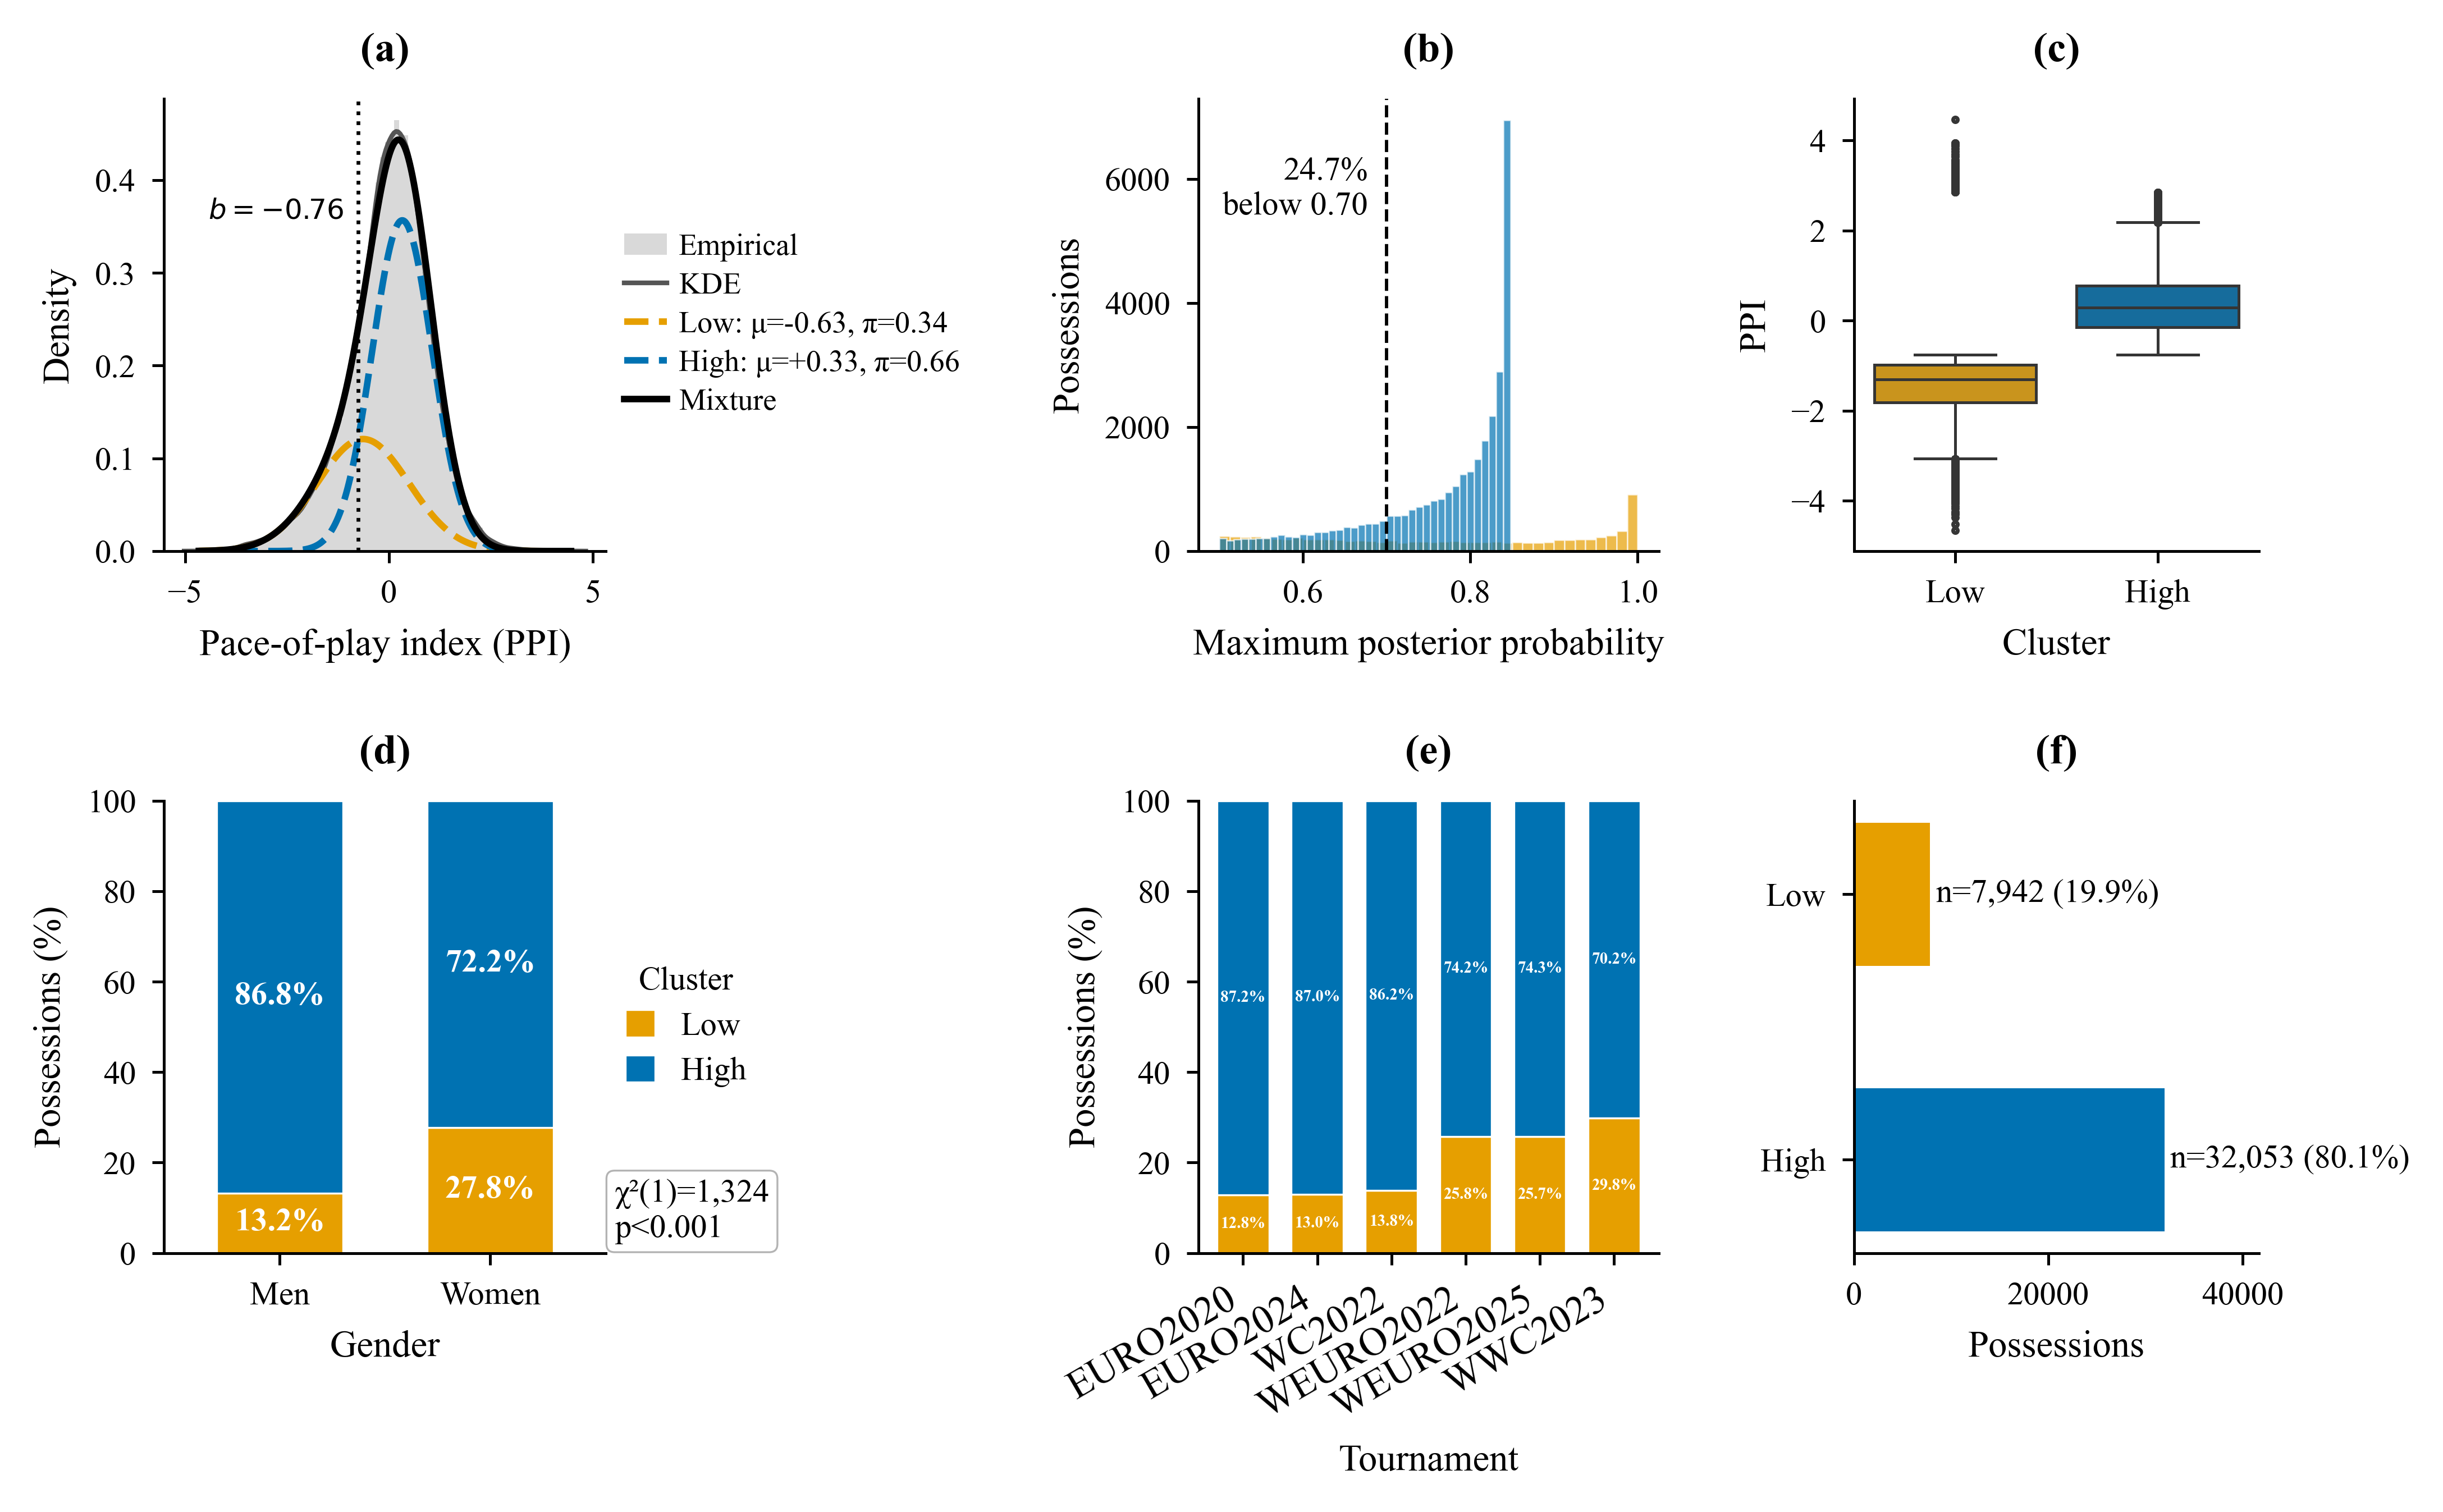

=== Posterior confidence ===
  mean = 0.766   median = 0.797
  24.7% rows max_prob < 0.70
  10.6% rows max_prob < 0.60

=== Decision boundaries on PPI ===
  PPI* = -0.760

=== χ²(gender × cluster) ===
  χ² = 1,323.6   dof = 1   p = 8.38e-290

=== Cluster composition (% within row) ===

• gender:
cluster   Low  High
gender             
Men      13.2  86.8
Women    27.8  72.2

• tournament (men-first):
cluster      Low  High
tournament            
EURO2020    12.8  87.2
EURO2024    13.0  87.0
WC2022      13.8  86.2
WEURO2022   25.8  74.2
WEURO2025   25.7  74.3
WWC2023     29.8  70.2


In [15]:
%config InlineBackend.figure_format = 'retina'
from scipy.stats import norm, chi2_contingency
import matplotlib as mpl

mpl.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Times New Roman"],
    "font.size":          8,
    "axes.titlesize":     9,
    "axes.labelsize":     8,
    "xtick.labelsize":    7,
    "ytick.labelsize":    7,
    "legend.fontsize":    7,
    "axes.linewidth":     0.6,
    "xtick.major.width":  0.6,
    "ytick.major.width":  0.6,
    "xtick.major.size":   2.5,
    "ytick.major.size":   2.5,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "legend.frameon":     False,
    "savefig.dpi":        300,
    "figure.dpi":         300
})

CLUSTER_COLOURS = {
    0: "#E69F00",  # Okabe-Ito orange  (slow, minority)
    1: "#0072B2",  # Okabe-Ito blue    (fast, majority)
    # 2: "#555555"
}
palette = [CLUSTER_COLOURS[k] for k in range(K_OPT_HORST)]
MIX_COLOUR = "#000000"   # mixture density — black
KDE_COLOUR = "#555555"   # empirical KDE — dark grey
HIST_COLOUR = "#BBBBBB"  # empirical histogram — light grey

K  = K_OPT_HORST
ti = result_horst["TI_horst"].values
mu, sd, pi = cluster_mu, cluster_sd, cluster_pi

xs = np.linspace(ti.min(), ti.max(), 4000)
xs_lab = np.vectorize(_remap.get)(gmm_final_horst.predict(xs.reshape(-1, 1)))
transitions = np.where(np.diff(xs_lab) != 0)[0]
_p1, _p99 = np.percentile(ti, [1, 99])
boundaries = [b for b in np.unique(xs[transitions].round(3)) if _p1 <= b <= _p99]

# ── figure: two-column width 180 mm × 110 mm 
fig, ax = plt.subplots(2, 3, figsize=(7.09, 4.33), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1.2, 1.25, 1.1]})

fig.set_constrained_layout_pads(w_pad=0.02, h_pad=0.02, wspace=0.10, hspace=0.10)

def panel_label(ax_, letter):
    ax_.set_title(f"({letter})", loc="center",
                  fontsize=9, fontweight="bold", pad=8)

# ── (a)  GMM density decomposition 
a = ax[0, 0]
a.hist(ti, bins=80, density=True, color=HIST_COLOUR, alpha=0.55,
       edgecolor="none", label="Empirical")
sns.kdeplot(ti, ax=a, color=KDE_COLOUR, lw=1.0, label="KDE")
mix = np.zeros_like(xs)
for k in range(K):
    comp = pi[k] * norm.pdf(xs, mu[k], sd[k])
    mix += comp
    comp_label = "Low" if k == 0 else "High"
    a.plot(xs, comp, "--", color=palette[k], lw=1.4,
           label=f"{comp_label}: μ={mu[k]:+.2f}, π={pi[k]:.2f}")
a.plot(xs, mix, color=MIX_COLOUR, lw=1.4, label="Mixture")
for b in boundaries:
    a.axvline(b, color=MIX_COLOUR, ls=":", lw=0.8)
    a.annotate(f"$b={b:+.2f}$", xy=(b, a.get_ylim()[1]*0.75),
               xytext=(-3, 0), textcoords="offset points",
               fontsize=6, va="center", ha="right",
               bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
a.set_xlabel("Pace-of-play index (PPI)")
a.set_ylabel("Density")
a.legend(loc="center left", bbox_to_anchor=(1.00, 0.5),
         handlelength=1.4, handletextpad=0.4, borderaxespad=0.2,
         labelspacing=0.35, fontsize=6.5)
panel_label(a, "a")

# ── (b)  Posterior confidence by cluster ────────────────────────────────────
a = ax[0, 1]
for k in range(K):
    sub = result_horst.loc[result_horst["cluster"]==k, "max_prob"]
    comp_label = "Low" if k == 0 else "High"
    a.hist(sub, bins=40, alpha=0.7, color=palette[k],
           label=comp_label, edgecolor="white", linewidth=0.3)
a.axvline(0.70, color="black", ls="--", lw=0.7)
low_conf = (result_horst["max_prob"] < 0.70).mean() * 100
a.annotate(f"{low_conf:.1f}%\nbelow 0.70",
           xy=(0.70, a.get_ylim()[1]*0.80), xytext=(-4, 0),
           textcoords="offset points",
           fontsize=7, ha="right", va="center",
           bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
a.set_xlabel("Maximum posterior probability")
a.set_ylabel("Possessions")
panel_label(a, "b")

# ── (c)  Within-cluster PPI boxplot ────────────────────────────────────────
a = ax[0, 2]
sns.boxplot(data=result_horst, x="cluster", y="TI_horst", hue="cluster",
            palette=palette, ax=a, fliersize=0.8, linewidth=0.6,
            legend=False)
a.set_xlabel("Cluster")
a.set_ylabel("PPI")
a.set_xticks(range(K)); a.set_xticklabels(["Low", "High"])
panel_label(a, "c")

# ── (d)  Cluster composition by gender (stacked %) ─────────────────────────
a = ax[1, 0]
g_comp = (pd.crosstab(result_horst["gender"], result_horst["cluster"],
                      normalize="index") * 100).round(1)
g_comp = g_comp.rename(columns={0: "Low", 1: "High"})
g_comp.plot(kind="bar", stacked=True, color=palette, ax=a,
            width=0.6, edgecolor="white", linewidth=0.4)
for c in a.containers:
    a.bar_label(c, label_type="center", fmt="%.1f%%",
                fontsize=7, color="white", fontweight="bold")
ct = pd.crosstab(result_horst["gender"], result_horst["cluster"])
chi2, p_val, dof, _ = chi2_contingency(ct)
a.text(1.02, 0.02, f"χ²({dof})={chi2:,.0f}\np<0.001",
       transform=a.transAxes, va="bottom", ha="left", fontsize=7,
       bbox=dict(facecolor="white", edgecolor="0.7", boxstyle="round,pad=0.25",
                 linewidth=0.4))
a.set_xlabel("Gender"); a.set_ylabel("Possessions (%)")
a.set_ylim(0, 100)
a.legend(title="Cluster", loc="center left", bbox_to_anchor=(1.00, 0.5),
         handlelength=0.9, handleheight=0.9, borderaxespad=0.2,
         labelspacing=0.4, title_fontsize=7)
a.tick_params(axis="x", rotation=0)
panel_label(a, "d")

# ── (e)  Cluster composition by tournament (stacked %) ─────────────────────
a = ax[1, 1]
t_comp = (pd.crosstab(result_horst["tournament"], result_horst["cluster"],
                      normalize="index") * 100).round(1)
t_comp = t_comp.rename(columns={0: "Low", 1: "High"})
_gender_by_t = result_horst.drop_duplicates("tournament").set_index("tournament")["gender"]
order = sorted(t_comp.index, key=lambda t: (_gender_by_t[t] == "Women", t))
t_comp = t_comp.loc[order]
t_comp.plot(kind="bar", stacked=True, color=palette, ax=a,
            width=0.7, edgecolor="white", linewidth=0.4, legend=False)
for c in a.containers:
    a.bar_label(c, label_type="center", fmt="%.1f%%",
                fontsize=3.5, color="white", fontweight="bold")
a.set_xlabel("Tournament"); a.set_ylabel("Possessions (%)")
a.set_ylim(0, 100)
a.tick_params(axis="x", rotation=30, labelsize=8.5)
for lbl in a.get_xticklabels():
    lbl.set_horizontalalignment("right")
panel_label(a, "e")


# ── (f)  Cluster sizes (horizontal bar instead of pie) ─────────────────────
a = ax[1, 2]
sizes = result_horst["cluster"].value_counts().sort_index()
pct   = sizes / sizes.sum() * 100
bars  = a.barh(["Low" if k == 0 else "High" for k in sizes.index], sizes.values,
               color=palette, edgecolor="white", linewidth=0.6, height=0.55)
for k, (rect, n, p) in enumerate(zip(bars, sizes.values, pct.values)):
    a.text(rect.get_width() + sizes.max()*0.015,
           rect.get_y() + rect.get_height()/2,
           f"n={n:,} ({p:.1f}%)",
           va="center", ha="left", fontsize=7)
a.set_xlabel("Possessions")
a.set_xlim(0, sizes.max() * 1.30)
a.invert_yaxis()
panel_label(a, "f")

for r in ax:
    for a in r:
        sns.despine(ax=a, trim=False)

plt.show()

# ── Text summary ────────────────────────────────────────────────────────────
print(f"=== Posterior confidence ===")
print(f"  mean = {result_horst['max_prob'].mean():.3f}   "
      f"median = {result_horst['max_prob'].median():.3f}")
print(f"  {(result_horst['max_prob']<0.70).mean()*100:.1f}% rows max_prob < 0.70")
print(f"  {(result_horst['max_prob']<0.60).mean()*100:.1f}% rows max_prob < 0.60")
print(f"\n=== Decision boundaries on PPI ===")
for b in boundaries:
    print(f"  PPI* = {b:+.3f}")
print(f"\n=== χ²(gender × cluster) ===")
print(f"  χ² = {chi2:,.1f}   dof = {dof}   p = {p_val:.2e}")
print(f"\n=== Cluster composition (% within row) ===")
print("\n• gender:")
print(g_comp.to_string())
print("\n• tournament (men-first):")
print(t_comp.to_string())


## Match-time distribution of pace of play

To illustrate how *Slow* and *High* pace possessions distribute across a full 90-minute match, we select
the final of each tournament and partition possessions into fixed 5-minute windows. Each panel shows the
percentage of possessions classified as *Slow* (orange) or *High* (blue) within each window.


In [ ]:
men_h5 = os.path.join(datafolder, "men-statsbomb.h5")

# 1. Load clustering results
df_cluster = pd.read_hdf(spadl_h5, "tactical_cluster_horst")

# 2. Select the final of each tournament
final_games = pd.DataFrame({
    "tournament": ["EURO2020", "EURO2024", "WC2022", "WEURO2022", "WEURO2025", "WWC2023"],
    "game_id":    [3795506,    3943043,    3869685, 3847567,     4020846,     3906390],
})
print("Selected finals:"); print(final_games)

# 3. Filter to selected games
df_sel = df_cluster.merge(final_games, on=["tournament", "game_id"])

# 4. Extract possession start times from raw events
possession_times = []
for row in df_sel[["game_id", "gender"]].drop_duplicates().itertuples():
    gid = row.game_id
    h5_file = men_h5 if row.gender == "Men" else spadl_h5
    try:
        events = pd.read_hdf(h5_file, f"events/game_{gid}")
        first_ev = (events[["possession", "minute", "second"]]
                    .groupby("possession").first().reset_index())
        first_ev["game_id"] = gid
        possession_times.append(first_ev)
    except Exception as e:
        print(f"  Error game {gid}: {e}")

all_times = pd.concat(possession_times, ignore_index=True)
df_sel = df_sel.merge(all_times, on=["game_id", "possession"], how="inner")
df_sel["match_minute"] = df_sel["minute"] + df_sel["second"] / 60.0

# 5. Remove possessions beyond 90 min
df_sel = df_sel[df_sel["match_minute"] <= 90].copy()

# 6. Create 5-minute bins (0-90 only, 18 bins)
bin_edges = list(range(0, 91, 5))  # [0, 5, 10, ..., 90]
labels_5 = [f"{bin_edges[i]}–{bin_edges[i+1]}" for i in range(len(bin_edges)-1)]
df_sel["minute_bin"] = pd.cut(df_sel["match_minute"], bins=bin_edges,
                               labels=labels_5, include_lowest=True)

df_sel["pace_label"] = df_sel["cluster"].map({0: "Low", 1: "High"})

# 7. Counts → percentages per bin
ct = (df_sel.groupby(["tournament", "minute_bin", "pace_label"], observed=False)
      .size().unstack(fill_value=0))
for col in ["Low", "High"]:
    if col not in ct.columns:
        ct[col] = 0
ct = ct[["Low", "High"]]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

# 8. Plot – 6 subplots (2 rows × 3 cols)
tourn_order = ["EURO2020", "EURO2024", "WC2022", "WEURO2022", "WEURO2025", "WWC2023"]
tourn_labels = {
    "EURO2020": "UEFA Euro 2020 (Men)",
    "EURO2024": "UEFA Euro 2024 (Men)",
    "WC2022":   "FIFA WC 2022 (Men)",
    "WEURO2022":"UEFA Euro 2022 (Women)",
    "WEURO2025":"UEFA Euro 2025 (Women)",
    "WWC2023":  "FIFA WC 2023 (Women)",
}

men_colours  = {"Low": "#D6EAF7", "High": "#6BAED6"}  
women_colours = {"Low": "#E6DAF2", "High": "#9E8AC3"} 
women_tourns = {"WEURO2022", "WEURO2025", "WWC2023"}

fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.8), dpi=300, sharey=True)

for idx, tourn in enumerate(tourn_order):
    ax = axes.flat[idx]
    sub = ct_pct.loc[tourn]
    x = np.arange(len(sub))
    bar_w = 0.8
    pal = women_colours if tourn in women_tourns else men_colours

    ax.bar(x, sub["Low"], width=bar_w, color=pal["Low"], label="Low")
    ax.bar(x, sub["High"], width=bar_w, bottom=sub["Low"],
           color=pal["High"], label="High")

    ax.set_title(tourn_labels.get(tourn, tourn), fontsize=8, fontweight="bold")
    ax.set_ylim(0, 100)
    ax.set_xticks(x[::3])
    ax.set_xticklabels(sub.index[::3], rotation=45, ha="right", fontsize=6)

    if idx % 3 == 0:
        ax.set_ylabel("Possessions (%)")
    if idx >= 3:
        ax.set_xlabel("Match Minute")

# Two-row legend: Men colours + Women colours
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=men_colours["Low"], label="Low (Men)"),
    Patch(facecolor=men_colours["High"], label="High (Men)"),
    Patch(facecolor=women_colours["Low"], label="Low (Women)"),
    Patch(facecolor=women_colours["High"], label="High (Women)"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 1.02), frameon=False, fontsize=7)

fig.suptitle("Pace of play distribution in tournament finals (5-min windows)",
             fontsize=9, fontweight="bold", y=1.07)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/pace_time_evolution.png", dpi=300, bbox_inches="tight")
plt.show()


## Component-feature preparation (winsorised, natural units)

Reproduces Step-1 preprocessing of `2-compute-features.ipynb` for the PPI component
features (fill structural NaN, directional sign-inversion, winsorise at [P1, P99]).
These winsorised features feed the pace-state profile below; **no z-scoring is applied
here** so the features stay in their natural units. The PPI itself is reported on the
standardised scale (`TI_horst`, mean 0, SD 1), consistent with its definition.

In [10]:
# ── Winsorised component features (natural units) for the pace-state profile ──
ALL_FEATURES = [
    "passes_per_minute", "distance_per_second", "distance_per_touch",
    "time_to_pass", "attacking_transition_time", "team_centroid_speed",
    "forward_progression_rate", "attack_rearline_variability", "team_spread_rate",
    "inter_team_longitudinal_dist", "pressing_frequency", "spatial_compression_x",
    "spatial_compression_y", "defensive_line_variability", "pass_completion_rate",
]
INVERT = {"time_to_pass", "attacking_transition_time"}          # higher = faster
FEATURES_FINAL = [                                              # 7 retained PPI components
    "passes_per_minute", "distance_per_second", "distance_per_touch",
    "time_to_pass", "spatial_compression_x", "spatial_compression_y",
    "pass_completion_rate",
]

cf = pd.read_hdf(spadl_h5, "combined_features")
raw_feat = cf[ALL_FEATURES].copy()
for col in ["attacking_transition_time", "time_to_pass"]:
    raw_feat[col] = raw_feat[col].fillna(raw_feat[col].quantile(0.95))
keep_idx = raw_feat.dropna().index
raw_feat = raw_feat.loc[keep_idx]
for col in INVERT:
    raw_feat[col] = -raw_feat[col]
for col in ALL_FEATURES:
    lo, hi = raw_feat[col].quantile(0.01), raw_feat[col].quantile(0.99)
    raw_feat[col] = raw_feat[col].clip(lo, hi)
print(f"Component features winsorised for {len(keep_idx):,} possessions.")

Component features winsorised for 39,995 possessions.


## PPI descriptive statistics — gender × tournament

Possession-level Pace-of-Play (`TI_horst`, standardised: mean 0, SD 1) by gender and
tournament, with per-gender and overall subtotals. Layout:
`Gender | Tournament | Year | No. of possessions | PPI, mean ± SD`.

In [11]:
# ── PPI (standardised TI_horst) descriptive table: gender × tournament ─────────
TOURN_META = {
    "EURO2020":  ("UEFA EURO",              2020),
    "WC2022":    ("FIFA World Cup",         2022),
    "EURO2024":  ("UEFA EURO",              2024),
    "WEURO2022": ("UEFA Women's EURO",      2022),
    "WWC2023":   ("FIFA Women's World Cup", 2023),
    "WEURO2025": ("UEFA Women's EURO",      2025),
}
GENDER_ORDER = {"Men": 0, "Women": 1}

ppi = efa_df.dropna(subset=["TI_horst"]).copy()

def _fmt(m, s):
    return f"{m:.3f} ± {s:.3f}"

rows = []
for tourn, (name, year) in TOURN_META.items():
    sub = ppi.loc[ppi["tournament"] == tourn, "TI_horst"]
    if sub.empty:
        continue
    gender = ppi.loc[ppi["tournament"] == tourn, "gender"].iloc[0]
    rows.append({"Gender": gender, "Tournament": name, "Year": str(year),
                 "No. of possessions": len(sub), "PPI, mean ± SD": _fmt(sub.mean(), sub.std()),
                 "_g": GENDER_ORDER[gender], "_y": year})
ppi_summary = pd.DataFrame(rows).sort_values(["_g", "_y"]).drop(columns=["_g", "_y"])

def _overall(series, gender, year_lbl):
    return {"Gender": gender, "Tournament": "—", "Year": year_lbl,
            "No. of possessions": len(series), "PPI, mean ± SD": _fmt(series.mean(), series.std())}

men_overall   = _overall(ppi.loc[ppi["gender"] == "Men",   "TI_horst"], "Men overall",   "2020–2024")
women_overall = _overall(ppi.loc[ppi["gender"] == "Women", "TI_horst"], "Women overall", "2022–2025")
grand_overall = _overall(ppi["TI_horst"],                                "Overall",       "2020–2025")

ppi_table = pd.concat([
    ppi_summary[ppi_summary["Gender"] == "Men"], pd.DataFrame([men_overall]),
    ppi_summary[ppi_summary["Gender"] == "Women"], pd.DataFrame([women_overall]),
    pd.DataFrame([grand_overall]),
], ignore_index=True)

print("=== PPI (standardised TI_horst) by gender × tournament ===")
print(ppi_table.to_string(index=False))
ppi_table.to_csv("figures/Table_PPI_by_gender_tournament.csv", index=False)
print("\n✅ saved → figures/Table_PPI_by_gender_tournament.csv")

=== PPI (standardised TI_horst) by gender × tournament ===
       Gender             Tournament      Year  No. of possessions PPI, mean ± SD
          Men              UEFA EURO      2020                6740  0.234 ± 0.921
          Men         FIFA World Cup      2022                8589  0.257 ± 0.958
          Men              UEFA EURO      2024                6456  0.262 ± 0.922
  Men overall                      — 2020–2024               21785  0.251 ± 0.936
        Women      UEFA Women's EURO      2022                4383 -0.269 ± 0.961
        Women FIFA Women's World Cup      2023                9410 -0.337 ± 1.015
        Women      UEFA Women's EURO      2025                4417 -0.253 ± 0.967
Women overall                      — 2022–2025               18210 -0.300 ± 0.991
      Overall                      — 2020–2025               39995 -0.000 ± 1.000

✅ saved → figures/Table_PPI_by_gender_tournament.csv


## Team-level PPI — UEFA Women's EURO 2025

Per-team Pace-of-Play (mean ± SD of the standardised `TI_horst`) for the 2025 Women's
EURO, aggregated over each team's possessions (`possession_team_id`).

In [12]:
# ── Team-level PPI (standardised TI_horst) — UEFA Women's EURO 2025 ────────────
teams_lkp = pd.read_hdf(spadl_h5, "teams")[["team_id", "team_name"]].drop_duplicates("team_id")
team_name = teams_lkp.set_index("team_id")["team_name"]

w25 = efa_df[(efa_df["gender"] == "Women") &
             (efa_df["tournament"] == "WEURO2025")].dropna(subset=["TI_horst"])

team_ppi = (w25.groupby("possession_team_id")["TI_horst"]
            .agg(n="count", mean="mean", sd="std").reset_index())
team_ppi["Team"] = (team_ppi["possession_team_id"].map(team_name)
                    .str.replace(" Women's", "", regex=False))
team_ppi["PPI, mean ± SD"] = team_ppi.apply(lambda r: f"{r['mean']:.3f} ± {r['sd']:.3f}", axis=1)
team_ppi = team_ppi.sort_values("mean", ascending=False)

table_b = (team_ppi[["Team", "n", "PPI, mean ± SD"]]
           .rename(columns={"n": "No. of possessions"}))

print(f"=== UEFA Women's EURO 2025 — team-level PPI (standardised TI_horst) "
      f"({len(table_b)} teams, {table_b['No. of possessions'].sum():,} possessions) ===")
print(table_b.to_string(index=False))
table_b.to_csv("figures/Table_PPI_WEURO2025_team_level.csv", index=False)
print("\n✅ saved → figures/Table_PPI_WEURO2025_team_level.csv")

=== UEFA Women's EURO 2025 — team-level PPI (standardised TI_horst) (16 teams, 4,417 possessions) ===
       Team  No. of possessions PPI, mean ± SD
    Belgium                 184 -0.033 ± 1.091
    England                 491 -0.119 ± 0.926
     Poland                 193 -0.139 ± 1.118
      Spain                 513 -0.178 ± 0.773
    Denmark                 171 -0.197 ± 0.974
Switzerland                 295 -0.204 ± 0.885
     France                 309 -0.231 ± 0.896
      Wales                 143 -0.232 ± 1.137
    Germany                 372 -0.234 ± 1.012
      Italy                 349 -0.241 ± 1.044
WNT Finland                 210 -0.333 ± 0.918
    Iceland                 201 -0.369 ± 1.050
Netherlands                 206 -0.372 ± 0.883
     Norway                 257 -0.388 ± 0.928
   Portugal                 200 -0.440 ± 0.890
     Sweden                 323 -0.494 ± 1.066

✅ saved → figures/Table_PPI_WEURO2025_team_level.csv


## Pace-state profile & per-feature thresholds

One table characterising the low vs high Pace state (GMM K=2 on `TI_horst`) across the 7
PPI component features. Features are winsorised at [P1, P99] and shown in natural units.
Per feature: mean ± SD within each state; Cohen's *d* = (mean_High − mean_Low)/pooled SD
(positive ⇒ higher in high pace; `time_to_pass` is naturally negative — faster pace ⇒ less
time to release); and the Youden's *J* high-pace cut-point, with Sens / Spec / Acc showing
how well that single feature reproduces the multivariate state.

In [13]:
# ── Combined pace-state profile + per-feature Youden thresholds ────────────────
from sklearn.metrics import roc_curve

# Winsorised features in natural units, joined to the GMM pace-state labels.
feat_proc = cf.loc[keep_idx, ["game_id", "possession", "possession_team_id"]].copy()
for f in FEATURES_FINAL:
    feat_proc[f] = (-raw_feat[f].values) if f in INVERT else raw_feat[f].values
prof = result_horst.merge(feat_proc, on=["game_id", "possession", "possession_team_id"])
n_lo = int((prof["cluster"] == 0).sum())
n_hi = int((prof["cluster"] == 1).sum())

def _cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp

rows = []
for f in FEATURES_FINAL:
    a = prof.loc[prof["cluster"] == 0, f].dropna()
    b = prof.loc[prof["cluster"] == 1, f].dropna()
    sub = prof[[f, "cluster"]].dropna()
    label = sub["cluster"].values                              # 1 = high pace
    score = -sub[f].values if f in INVERT else sub[f].values   # orient: higher = faster
    fpr, tpr, thr = roc_curve(label, score)
    j = int(np.argmax(tpr - fpr))                              # Youden's J
    cut = -thr[j] if f in INVERT else thr[j]                   # back to natural units
    acc = ((score >= thr[j]).astype(int) == label).mean()
    side = "<" if f in INVERT else ">"
    rows.append({
        "Variable": f,
        f"Low pace (n={n_lo:,})":  f"{a.mean():.3f} ± {a.std():.3f}",
        f"High pace (n={n_hi:,})": f"{b.mean():.3f} ± {b.std():.3f}",
        "Cohen d": round(_cohen_d(a, b), 2),
        "High-pace rule": f"{side} {cut:.2f}",
        "Sens": round(tpr[j], 3),
        "Spec": round(1 - fpr[j], 3),
        "Acc":  round(acc, 3),
    })
profile_table = pd.DataFrame(rows)

# GMM decision boundary on the standardised PPI (TI_horst) axis (posterior = 0.5)
s = result_horst.sort_values("TI_horst")
ti, dpc = s["TI_horst"].values, (s["p_C1"] - 0.5).values
xb = [ti[i-1] + (ti[i]-ti[i-1])*(0-dpc[i-1])/(dpc[i]-dpc[i-1])
      for i in range(1, len(dpc)) if (dpc[i-1] < 0 <= dpc[i]) or (dpc[i-1] >= 0 > dpc[i])]
boundary = round(min(xb), 3) if xb else float("nan")

print("=== Pace-state profile & per-feature thresholds (GMM K=2 on TI_horst) ===")
print(f"Low pace n={n_lo:,} | High pace n={n_hi:,} | "
      f"slow/fast boundary at TI_horst = {boundary} (posterior = 0.5)")
print(profile_table.to_string(index=False))
profile_table.to_csv("figures/Table_pace_state_feature_profile.csv", index=False)
print("\n✅ saved → figures/Table_pace_state_feature_profile.csv")

=== Pace-state profile & per-feature thresholds (GMM K=2 on TI_horst) ===
Low pace n=7,942 | High pace n=32,053 | slow/fast boundary at TI_horst = -0.758 (posterior = 0.5)
             Variable Low pace (n=7,942) High pace (n=32,053)  Cohen d High-pace rule  Sens  Spec   Acc
    passes_per_minute     13.746 ± 5.961       21.054 ± 7.305     1.04        > 15.48 0.816 0.674 0.788
  distance_per_second      7.854 ± 2.768        9.017 ± 2.419     0.47         > 7.24 0.805 0.451 0.734
   distance_per_touch     12.429 ± 6.712       13.732 ± 5.976     0.21        > 10.25 0.746 0.431 0.683
         time_to_pass      5.334 ± 1.715        3.239 ± 1.122    -1.66         < 4.23 0.849 0.729 0.826
spatial_compression_x      7.226 ± 1.580        8.845 ± 1.724     0.95         > 7.98 0.691 0.699 0.692
spatial_compression_y     11.762 ± 2.538       14.902 ± 2.955     1.09        > 13.61 0.679 0.775 0.698
 pass_completion_rate      0.616 ± 0.336        0.823 ± 0.184     0.93         > 0.72 0.761 0.579 0.

## Persist clustered output

Write the labelled possession-level table to `tactical_cluster_horst` in the women H5 for downstream analysis.

In [14]:
cluster_cols = ["cluster", "max_prob"] + [f"p_C{k}" for k in range(K_OPT_HORST)]
save_cols = ["game_id", "possession", "possession_team_id",
             "tournament", "gender", "TI_horst"] + cluster_cols
out = result_horst[save_cols].copy()
out.to_hdf(spadl_h5, key="tactical_cluster_horst", mode="a", complevel=5)
print(f"✅ saved tactical_cluster_horst → {spadl_h5}  ({len(out):,} rows × {len(save_cols)} cols)")
print(out.head(3))

✅ saved tactical_cluster_horst → ../data/women-statsbomb3.h5  (39,995 rows × 10 cols)
   game_id  possession  possession_team_id tournament gender  TI_horst  \
0  4020846           2                 865  WEURO2025  Women  1.143743   
1  4020846           4                 865  WEURO2025  Women  0.737501   
2  4020846           5                 865  WEURO2025  Women  1.003642   

   cluster  max_prob      p_C0      p_C1  
0        1  0.847192  0.152808  0.847192  
1        1  0.841297  0.158703  0.841297  
2        1  0.847741  0.152259  0.847741  
